# Account takeover (ATO) detection & login risk scoring — walkthrough

This notebook walks through the data, the behavioural signals, the model comparison
and one alert investigation. The heavy lifting lives in `src/ato/`; run
`python scripts/run_pipeline.py` first.

> **Data note.** The login telemetry is **synthetic** (schema of the public RBA dataset),
> generated with known attack campaigns so every number here is reproducible.
> Results describe this simulation, not a production system.

In [1]:
import json, sys
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
from ato.features import build_features, FEATURES
from ato.rules import rule_hits, RULES
from ato.report import _style, SERIES, TIER, INK2
_style()
pd.set_option("display.width", 140, "display.max_columns", 20)

events = pd.read_csv(ROOT / "data/login_events.csv.gz", parse_dates=["login_ts"])
metrics = json.loads((ROOT / "reports/metrics.json").read_text())
print(f"{len(events):,} login events | {events.user_id.nunique():,} users | "
      f"{events.login_ts.min():%d %b} – {events.login_ts.max():%d %b %Y}")
events.head(3).T

332,869 login events | 2,500 users | 01 May – 28 Aug 2026


,0,1,2
login_ts,2026-05-01 00:01:04,2026-05-01 00:01:40,2026-05-01 00:02:23
user_id,u00092,u00952,u01381
ip,24.86.193.81,112.138.62.231,11.18.178.198
country,ID,ID,ID
region,Riau,DKI Jakarta,Bali
city,Pekanbaru,Jakarta,Denpasar
asn,4761,23700,23700
asn_name,Indosat Ooredoo Hutchison,Link Net (First Media),Link Net (First Media)
asn_type,mobile,fixed,fixed
user_agent,"Mozilla/5.0 (iPhone; CPU iPhone OS 17_5 like Mac OS X) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/17.5 Mobile/15E148 Safari/604.1","Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Version/17.6 Safari/605.1.15","Mozilla/5.0 (Windows NT 10.0; Win64; x64) AppleWebKit/537.36 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36"


## 1. What is in the log?

Most traffic is ordinary. The interesting part is the **legitimate noise** — travel,
VPNs, new phones, typos — because that is what generates false positives.

In [2]:
summary = (events.groupby("scenario")
           .agg(events=("user_id", "size"),
                success_rate=("login_successful", "mean"),
                takeovers=("is_account_takeover", "sum"))
           .sort_values("events", ascending=False))
summary["success_rate"] = (100 * summary["success_rate"]).round(1)
summary

,events,success_rate,takeovers
scenario,,,
normal,293374,100.0,0
typo,22189,0.0,0
credential_stuffing,7097,5.1,365
forgot_password,2728,0.0,0
vpn,2150,100.0,0
brute_force,2057,0.2,5
travel_domestic,1488,100.0,0
new_device,788,100.0,0
travel_abroad,682,100.0,0


## 2. Point-in-time features

Each login is compared only with the user's **earlier** successful logins
(and the IP's/ASN's earlier attempts) — exactly what a real-time engine would know.
A unit test (`tests/test_pipeline.py::test_features_are_point_in_time`) proves that adding
future events never changes a past feature.

In [3]:
feat = build_features(events)
scored = feat[(feat.login_successful == 1) & (feat.login_ts >= feat.login_ts.min().normalize() + pd.Timedelta(days=14))]
cols = ["new_device", "new_country", "new_asn", "dist_first_km", "geo_velocity_kmh",
        "hour_deviation", "user_fails_24h", "is_hosting_asn", "country_global_share"]
cmp = scored.groupby("is_account_takeover")[cols].mean().T
cmp.columns = ["legit (mean)", "takeover (mean)"]
cmp.round(3)

,legit (mean),takeover (mean)
new_device,0.002,0.445
new_country,0.000,0.415
new_asn,0.002,0.520
dist_first_km,85.402,6194.882
geo_velocity_kmh,27.207,1224.209
hour_deviation,2.751,5.767
user_fails_24h,0.247,0.705
is_hosting_asn,0.007,0.406
country_global_share,0.981,0.321


## 3. Why simple rules are not enough

Classic SIEM rules fire on *legitimate* behaviour too. Impossible-travel looks great on paper,
but VPN users hopping between Jakarta and an Amsterdam exit node, or travellers alternating
between roaming and hotel Wi-Fi, trip it constantly.

In [4]:
rc = pd.DataFrame(metrics["rule_coverage_test"]).set_index("rule")
rc[["points", "fires_per_day", "precision_pct", "ato_coverage_pct"]]

,points,fires_per_day,precision_pct,ato_coverage_pct
rule,,,,
R01_IMPOSSIBLE_TRAVEL,40,8.1,10.5,20.0
R02_NEW_COUNTRY_NEW_DEVICE,35,1.2,100.0,27.8
R03_AUTOMATION_UA,50,0.0,100.0,1.1
R04_FAILED_BURST_USER,35,0.6,7.7,1.1
R05_IP_SPRAY,40,2.2,13.0,6.7
R06_HOSTING_ASN,20,19.3,7.9,35.6
R07_NEW_DEVICE_NEW_NETWORK,20,1.7,100.0,38.9
R08_RARE_COUNTRY,15,2.3,63.3,34.4
R09_ODD_HOUR,10,265.2,0.6,37.8


In [5]:
hits = rule_hits(scored)
noise = (pd.concat([scored[["scenario", "is_account_takeover"]], hits["R01_IMPOSSIBLE_TRAVEL"]], axis=1)
         .query("R01_IMPOSSIBLE_TRAVEL"))
noise.groupby("scenario").size().sort_values(ascending=False).rename("impossible-travel hits")

scenario
normal                 448
vpn                    383
travel_abroad           83
credential_stuffing     64
targeted_ato            47
new_device               5
travel_domestic          3
brute_force              1
Name: impossible-travel hits, dtype: int64

## 4. Model comparison on the unseen test period

All four detectors go through the **same** policy machinery: thresholds are picked on the
validation weeks by minimising expected cost, then frozen and applied to the test weeks.

In [6]:
rows = {k: {"PR-AUC": v["pr_auc"], "ATO intercepted %": v["ato_intercepted_pct"],
            "ATO blocked %": v["ato_blocked_pct"], "legit MFA %": v["legit_mfa_rate_pct"],
            "legit blocked %": v["legit_blocked_rate_pct"], "HIGH alerts/day": v["high_alerts_per_day"],
            "HIGH precision %": v["high_alert_precision_pct"],
            "cost (Rp jt)": round(v["expected_cost_idr"] / 1e6, 1)}
        for k, v in metrics["test_comparison"].items()}
pd.DataFrame(rows).T

,PR-AUC,ATO intercepted %,ATO blocked %,legit MFA %,legit blocked %,HIGH alerts/day,HIGH precision %,cost (Rp jt)
Rules only,0.3781,75.6,32.2,0.987,0.0211,1.9,72.5,217.3
Isolation Forest only,0.4133,83.3,0.0,1.856,0.0000,0.0,0.0,199.3
Gradient boosting only,0.9092,96.7,81.1,1.503,0.0000,3.5,100.0,43.1
Hybrid (stacked),0.9098,96.7,81.1,1.568,0.0038,3.6,97.3,44.3


In [7]:
print("Stacker weights (logistic regression on out-of-fold signals):")
for k, v in metrics["stacker_weights"].items():
    print(f"  {k:18s} {v:+.3f}")

Stacker weights (logistic regression on out-of-fold signals):
  ml_logit           +1.006
  anomaly_pct        +0.734
  rule_points/100    +0.100
  intercept          +0.682


## 5. Who gets challenged? Legit noise vs attacks

The score should push genuine-but-unusual users (travel, VPN, new phone) into **step-up MFA**,
not into a block — while takeovers land in the block tier.

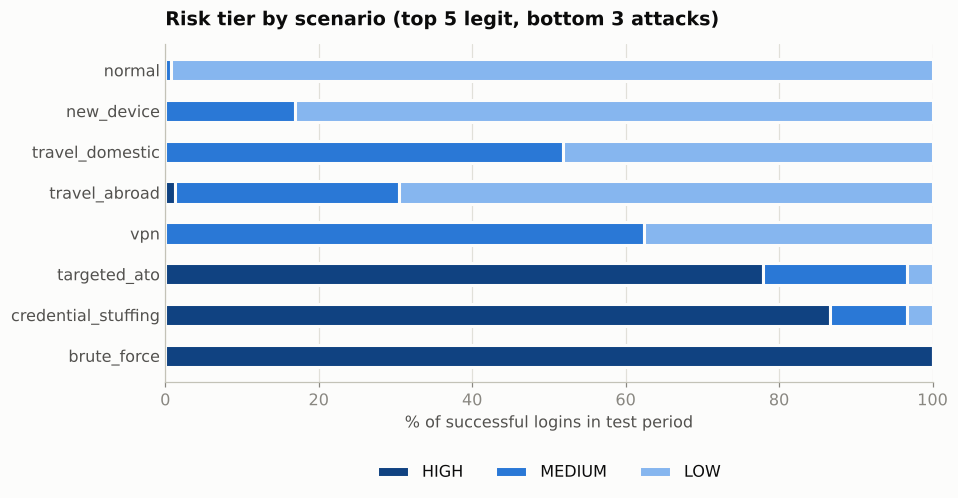

tier,LOW,MEDIUM,HIGH
scenario,,,
normal,99.2,0.8,0.0
new_device,83.1,16.9,0.0
travel_domestic,48.1,51.9,0.0
travel_abroad,69.5,29.3,1.2
vpn,37.6,62.4,0.0
targeted_ato,3.4,18.6,78.0
credential_stuffing,3.3,10.0,86.7
brute_force,0.0,0.0,100.0


In [8]:
st = pd.read_csv(ROOT / "reports/scored_test.csv.gz")
order = ["normal", "new_device", "travel_domestic", "travel_abroad", "vpn",
         "targeted_ato", "credential_stuffing", "brute_force"]
mix = (st.groupby("scenario")["tier"].value_counts(normalize=True).unstack(fill_value=0)
         .reindex(index=order, columns=["LOW", "MEDIUM", "HIGH"], fill_value=0) * 100)

fig, ax = plt.subplots(figsize=(9, 4))
left = np.zeros(len(mix))
for tier in ["HIGH", "MEDIUM", "LOW"]:
    ax.barh(mix.index, mix[tier], left=left, color=TIER[tier], height=0.55,
            edgecolor="#fcfcfb", linewidth=2, label=tier)
    left += mix[tier].to_numpy()
ax.invert_yaxis(); ax.set_xlim(0, 100); ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", colors=INK2, length=0)
ax.set_xlabel("% of successful logins in test period")
ax.set_title("Risk tier by scenario (top 5 legit, bottom 3 attacks)")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.2))
plt.show()
mix.round(1)

## 6. Alert investigation (mini post-incident review)

Take one HIGH alert emitted in ECS format and reconstruct the account's timeline —
the evidence an analyst (or auditor) would attach to the case.

In [9]:
alerts = [json.loads(l) for l in open(ROOT / "reports/alerts_test.jsonl")]
high = [a for a in alerts if a["risk"]["calculated_level"] == "high"]
case = next(a for a in high if "R02_NEW_COUNTRY_NEW_DEVICE" in a["ato"]["reasons"])
print(json.dumps(case, indent=2)[:1800])

{
  "@timestamp": "2026-08-10T00:09:38+07:00",
  "event": {
    "kind": "alert",
    "category": [
      "authentication"
    ],
    "type": [
      "start"
    ],
    "outcome": "success",
    "action": "block_session_and_reset_password",
    "severity": 73
  },
  "user": {
    "name": "u01908"
  },
  "source": {
    "ip": "132.214.79.73",
    "geo": {
      "country_iso_code": "RU",
      "region_name": "Moscow",
      "city_name": "Moscow"
    },
    "as": {
      "number": 12389,
      "organization": {
        "name": "Rostelecom"
      }
    }
  },
  "user_agent": {
    "original": "Mozilla/5.0 (Macintosh; Intel Mac OS X 10_15_7) AppleWebKit/605.1.15 (KHTML, like Gecko) Chrome/128.0.0.0 Safari/537.36",
    "device": {
      "name": "desktop"
    }
  },
  "risk": {
    "calculated_score": 100.0,
    "calculated_level": "high",
    "calculated_score_norm": 0.999941
  },
  "rule": {
    "name": "Account takeover risk",
    "ruleset": "ato-risk-engine 1.0.0",
    "reference": "docs/a

In [10]:
uid = case["user"]["name"]
t = pd.Timestamp(case["@timestamp"][:19])
tl = (events[(events.user_id == uid) & events.login_ts.between(t - pd.Timedelta(days=4), t + pd.Timedelta(days=2))]
      [["login_ts", "login_successful", "city", "country", "asn_name", "browser", "os", "device_id",
        "is_account_takeover"]])
tl

,login_ts,login_successful,city,country,asn_name,browser,os,device_id,is_account_takeover
272150,2026-08-06 23:27:01,1,Surabaya,ID,Telkomsel,Safari 17.6,Mac OS X 14.6,d_32c95f1093a9,0
276940,2026-08-08 20:45:14,1,Surabaya,ID,Link Net (First Media),Safari 17.6,Mac OS X 14.6,d_32c95f1093a9,0
279423,2026-08-09 22:21:12,1,Surabaya,ID,Link Net (First Media),Samsung Internet 25.0,Android 14,d_0de36f47143d,0
279652,2026-08-10 00:09:38,1,Moscow,RU,Rostelecom,Chrome 128.0,Mac OS X 14.6,d_d9731c5e50c0,1
281758,2026-08-10 20:11:55,1,Surabaya,ID,Link Net (First Media),Safari 17.6,Mac OS X 14.6,d_32c95f1093a9,0
282259,2026-08-10 22:15:33,1,Surabaya,ID,Link Net (First Media),Samsung Internet 25.0,Android 14,d_0de36f47143d,0
284808,2026-08-11 20:57:47,1,Surabaya,ID,Telkomsel,Samsung Internet 25.0,Android 14,d_0de36f47143d,0


**Reading the timeline:** the account's history is a stable device on Indonesian networks;
the flagged session uses an unseen device from a different country, which the engine blocked and
sent to the SOC with reason codes. Follow-up per `docs/alert_playbook.md`: confirm with the
customer, revoke sessions, reset credentials, and add the infrastructure to the blocklist.

## 7. Limitations & next steps
- Synthetic data: attackers here are simpler than real adversaries; validate on the real RBA dataset
  (similar schema; needs a geo lookup and an ASN-type list — see README) and on production logs
  before trusting any number.
- Labels in reality arrive late and incomplete (chargebacks, customer reports) → monitor with delayed
  labels and keep the unsupervised layer as a safety net.
- Friction and score distributions drift as behaviour changes → weekly monitoring (PSI) and recalibration.
- Next: device fingerprint reputation, graph features (accounts sharing devices/IPs), Kibana dashboard.